[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/03-detector-fake-news-naive-bayes.ipynb)

# Detector de noticia falsa com Naive Bayes

O conjunto e o de George McIntire, de 2016: noticias em ingles marcadas como reais ou falsas, juntando materias de veiculos e textos que circulavam como boato. Nao pede login do Kaggle. O CSV usado aqui e o espelho de ensino mantido em `github.com/lutzhamel/fake-news` (`data/fake_or_real_news.csv`), porque o repositorio original de McIntire nao publica mais o arquivo cru. As colunas sao `id`, `title`, `text` e `label` (`REAL` ou `FAKE`).

O modelo le titulo e corpo juntos. Isso e uma escolha: o titulo sozinho ja carrega muito sinal, e tambem muito vies de assunto (nomes de uma eleicao, por exemplo). O caderno nao trata o resultado como um detector pronto para a internet.


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

No grupo da familia chega um texto com titulo alarmista. A pessoa olha duas coisas antes de abrir: o assunto e o tom. "Urgente", nome de politico e promessa de segredo puxam para um lado; "segundo o instituto" e "dados do ministerio" puxam para o outro. E um filtro grosseiro. Ele confunde assunto com veracidade: uma noticia real sobre o mesmo politico herda as palavras do boato.

O Naive Bayes faz exatamente esse filtro grosseiro, e por isso serve para estudar o metodo e para ver o limite dele.


## 2) Fundamentação matemática

O teorema de Bayes inverte a pergunta. Em vez de perguntar so quao tipico e o texto dentro de uma classe, calculamos a chance da classe depois de ler o texto:

$$
P(y \mid x) = \frac{P(x \mid y)\, P(y)}{P(x)}
$$

- $P(y \mid x)$ e a probabilidade da classe $y$ depois de observar $x$. E a saida do classificador.
- $P(x \mid y)$ e a verossimilhanca: a chance de ver esse texto se a classe for $y$.
- $P(y)$ e o prior, a frequencia da classe antes de olhar o texto.
- $P(x)$ e a evidencia. Ela nao depende de $y$, entao nao muda qual classe ganha. Na hora de decidir, comparamos $P(x \mid y)\,P(y)$.

A hipotese de independencia condicional, a parte ingênua do nome, diz que, dada a classe, uma palavra nao informa a outra:

$$
P(x \mid y) = \prod_{j=1}^{d} P(x_j \mid y)
$$

- $x_j$ e a contagem da palavra $j$.
- $d$ e o tamanho do vocabulario.
- O produto e falso em frases reais ("nao" muda "bom"), mas o erro muitas vezes se reparte e o sinal de cada palavra ainda aponta a classe certa.

No modelo multinomial a probabilidade de uma palavra e a fatia dela nas contagens da classe. A suavizacao de Laplace soma $\alpha$ para uma palavra nunca vista nao zerar o produto inteiro:

$$
\hat{P}(w \mid y) = \frac{n_{y,w} + \alpha}{n_y + \alpha \, |V|}
$$

- $n_{y,w}$ e quantas vezes a palavra $w$ apareceu na classe $y$.
- $n_y$ e a soma de todas as contagens da classe.
- $|V|$ e o numero de palavras do vocabulario.
- $\alpha$ e a forca da suavizacao. Com $\alpha = 1$ ha uma ocorrencia ficticia de cada palavra em cada classe.

Mil probabilidades pequenas, multiplicadas, estouram para zero no computador. O logaritmo transforma o produto em soma:

$$
\log P(y \mid x) \propto \log P(y) + \sum_{j=1}^{d} x_j \, \log \hat{P}(w_j \mid y)
$$

- $\log P(y)$ e o prior em escala de log.
- $x_j \log \hat{P}(w_j \mid y)$ pesa a palavra pela contagem dela neste texto. Palavra ausente entra com zero.
- A classe escolhida e a de maior soma. Para converter as somas em probabilidades que somam 1, subtraimos o log-sum-exp de todas as classes.

Aqui o prior importa de novo. Se o arquivo tiver mais textos `FAKE` do que `REAL`, $\log P(y)$ ja larga o boato na frente. A secao de avaliacao compara o modelo com o chute da classe majoritaria para esse efeito nao passar batido.


## 3) Visualização

Classe positiva no resto do caderno: `FAKE` = 1. Os textos continuam em ingles, como na fonte.


linhas 6335
label
REAL    3171
FAKE    3164
Name: count, dtype: int64
fonte: George McIntire, 2016, espelho lutzhamel/fake-news


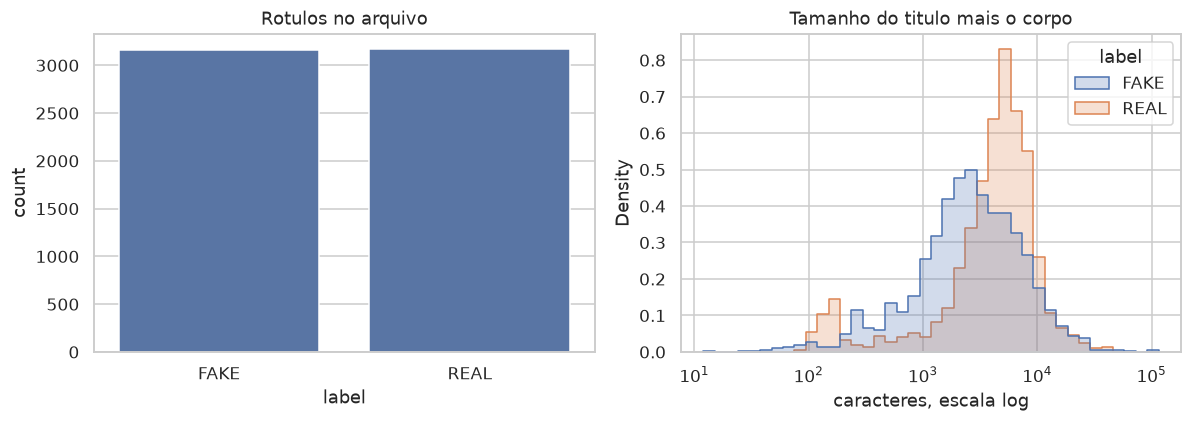

treino 4751 teste 1584


In [2]:
arquivo = baixar(
    "https://raw.githubusercontent.com/lutzhamel/fake-news/master/data/fake_or_real_news.csv",
    PASTA_DADOS / "fake_or_real_news.csv",
)
df = pd.read_csv(arquivo)
df["texto"] = (df["title"].fillna("") + "\n" + df["text"].fillna("")).str.strip()
df = df[df["texto"].str.len() > 0].copy()
df["label"] = df["label"].str.strip().str.upper()
df["y"] = (df["label"] == "FAKE").astype(int)
df["tamanho"] = df["texto"].str.len()
print("linhas", len(df))
print(df["label"].value_counts())
print("fonte: George McIntire, 2016, espelho lutzhamel/fake-news")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="label", ax=eixos[0], color="#4c72b0")
eixos[0].set_title("Rotulos no arquivo")
sns.histplot(data=df, x="tamanho", hue="label", bins=40, element="step", stat="density", log_scale=(True, False), ax=eixos[1])
eixos[1].set_title("Tamanho do titulo mais o corpo")
eixos[1].set_xlabel("caracteres, escala log")
plt.tight_layout()
plt.show()

from sklearn.model_selection import train_test_split

X_treino_txt, X_teste_txt, y_treino, y_teste = train_test_split(
    df["texto"].tolist(), df["y"].to_numpy(), test_size=0.25, random_state=0, stratify=df["y"].to_numpy(),
)
print("treino", len(y_treino), "teste", len(y_teste))


## 4) Implementação do zero

Quatro mil palavras mais frequentes. Laplace com $\alpha = 1$. O grafico mostra a diferenca de log-probabilidade, nao a "verdade" da palavra: "clinton" separar classes neste arquivo diz algo sobre o arquivo de 2016, nao sobre a palavra em geral.


matriz (4751, 4000)


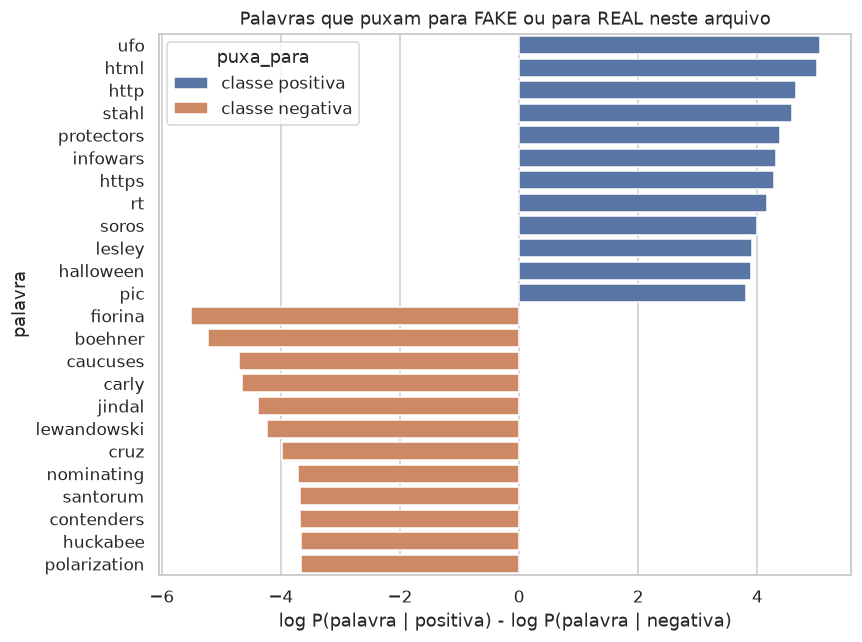

In [3]:
from mlalgos import BagOfWords, MultinomialNB

vetor = BagOfWords(max_features=4000)
X_treino = vetor.fit_transform(X_treino_txt)
X_teste = vetor.transform(X_teste_txt)
nb = MultinomialNB(alpha=1.0).fit(X_treino, y_treino)
print("matriz", X_treino.shape)
indice = {classe: i for i, classe in enumerate(nb.classes_)}
delta = nb.feature_log_prob_[indice[1]] - nb.feature_log_prob_[indice[0]]
vocabulario = np.empty(len(vetor.vocabulary_), dtype=object)
for token, coluna in vetor.vocabulary_.items():
    vocabulario[coluna] = token
ordem = np.argsort(delta)
k = 12
tabela = pd.DataFrame({
    "palavra": np.concatenate([vocabulario[ordem[-k:][::-1]], vocabulario[ordem[:k]]]),
    "diferenca_de_log": np.concatenate([delta[ordem[-k:][::-1]], delta[ordem[:k]]]),
    "puxa_para": ["classe positiva"] * k + ["classe negativa"] * k,
})
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=tabela, y="palavra", x="diferenca_de_log", hue="puxa_para", dodge=False, ax=ax)
ax.set_title('Palavras que puxam para FAKE ou para REAL neste arquivo')
ax.set_xlabel("log P(palavra | positiva) - log P(palavra | negativa)")
plt.tight_layout()
plt.show()


## 5) Implementação com scikit-learn

Mesma matriz nos dois `MultinomialNB`. O pipeline repete o fluxo com as classes do scikit-learn.


In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB as SkMultinomialNB
from sklearn.pipeline import Pipeline

sk = SkMultinomialNB(alpha=1.0).fit(X_treino, y_treino)
diferenca = np.max(np.abs(nb.predict_proba(X_teste) - sk.predict_proba(X_teste)))
acordo = float(np.mean(nb.predict(X_teste) == sk.predict(X_teste)))
print(f"maior diferenca absoluta entre probabilidades: {diferenca:.3e}")
print(f"concordancia das classes previstas: {acordo:.3f}")

cano = Pipeline([
    ("contagem", CountVectorizer(max_features=4000)),
    ("nb", SkMultinomialNB(alpha=1.0)),
])
cano.fit(X_treino_txt, y_treino)
print("acuracia do pipeline no teste", float(cano.score(X_teste_txt, y_teste)))


maior diferenca absoluta entre probabilidades: 1.421e-14
concordancia das classes previstas: 1.000


acuracia do pipeline no teste 0.865530303030303


## 6) Avaliação

Classe positiva = noticia marcada como `FAKE` no arquivo. Um F1 alto neste conjunto nao autoriza usar o modelo como arbitro de verdade: ele aprendeu o vocabulario de uma eleicao e de um punhado de sites.


acuracia 0.866 | baseline da classe majoritaria 0.501
precisao 0.870 | revocacao 0.860 | f1 0.865 | roc_auc 0.910
RESUMO_METRICAS {"modelo": "multinomial_nb_fake_news", "acuracia": 0.865530303030303, "precisao": 0.8695652173913043, "revocacao": 0.8596713021491783, "f1": 0.8645899554990464, "roc_auc": 0.9104745537358333, "baseline_majoritaria": 0.5006313131313131}


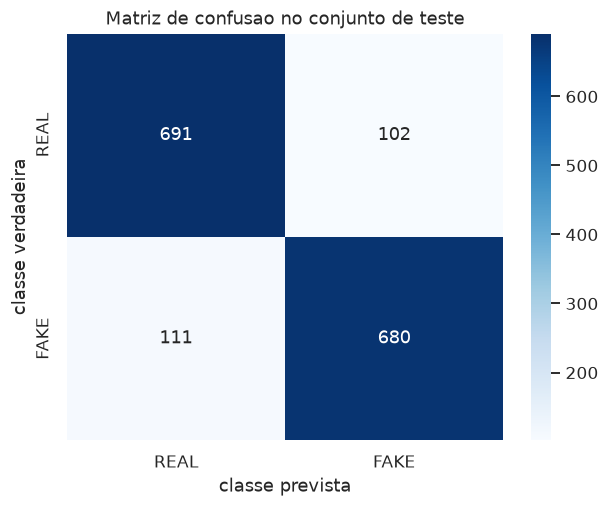

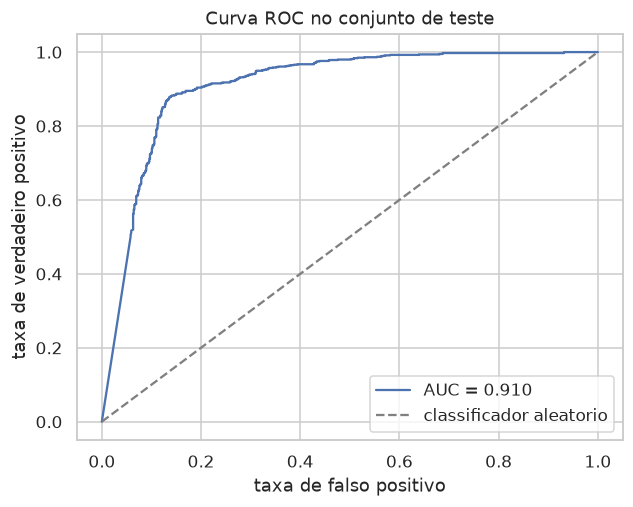

In [5]:
from mlalgos.metrics import confusion_matrix, curva_roc, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = nb.predict(X_teste)
y_escore = nb.predict_proba(X_teste)[:, 1]
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, pos_label=1)
revocacao = recall_score(y_teste, y_previsto, pos_label=1)
f1 = f1_score(y_teste, y_previsto, pos_label=1)
auc = roc_auc_score(y_teste, y_escore, pos_label=1)
baseline = float(max(np.mean(y_teste == 1), np.mean(y_teste == 0)))
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao {precisao:.3f} | revocacao {revocacao:.3f} | f1 {f1:.3f} | roc_auc {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'multinomial_nb_fake_news',
    "acuracia": acuracia,
    "precisao": precisao,
    "revocacao": revocacao,
    "f1": f1,
    "roc_auc": auc,
    "baseline_majoritaria": baseline,
}))

cm = confusion_matrix(y_teste, y_previsto, labels=[0, 1])
fig, ax = plt.subplots()
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=['REAL', 'FAKE'], yticklabels=['REAL', 'FAKE'], ax=ax,
)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()

fpr, tpr, _ = curva_roc(y_teste, y_escore, pos_label=1)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="classificador aleatorio")
ax.set_xlabel("taxa de falso positivo")
ax.set_ylabel("taxa de verdadeiro positivo")
ax.set_title("Curva ROC no conjunto de teste")
ax.legend()
plt.show()


## 7) Desafios

1. Treine de novo usando so a coluna `title`. Quanto o F1 cai? O que isso diz sobre o sinal estar no corpo ou na manchete?
2. Olhe as 12 palavras que mais puxam para `FAKE`. Quantas sao nomes proprios ou marcas de uma epoca? Reescreva, em uma frase, o que o modelo de fato aprendeu.
3. Mude o limiar de 0,5 para 0,7 na probabilidade de `FAKE` e recalcule precisao e revocacao. Qual dos dois erros voce aceitaria num produto que avisa o leitor?
